# Task 5 – Email spam detection with KNN and SVM
Normal state = **Not spam (0)**, Abnormal state = **Spam (1)**.

In [1]:
import time, numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, classification_report, ConfusionMatrixDisplay)
import warnings; warnings.filterwarnings("ignore")

df = pd.read_csv("emails.csv")
print("Shape:", df.shape)
df.iloc[:5, :8]

Shape: (5172, 3002)


,Email No.,the,to,ect,and,for,of,a
0,Email 1,0,0,1,0,0,0,2
1,Email 2,8,13,24,6,6,2,102
2,Email 3,0,0,1,0,0,0,8
3,Email 4,0,5,22,0,5,1,51
4,Email 5,7,6,17,1,5,2,57


Missing values: 0


Duplicate rows: 541

Class counts:
 Prediction
Not spam    3672
Spam        1500
Name: count, dtype: int64


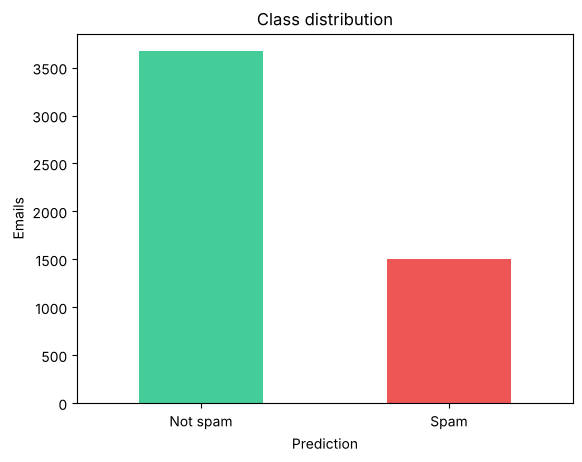

In [2]:
print("Missing values:", df.isnull().sum().sum())
print("Duplicate rows:", df.drop(columns="Email No.").duplicated().sum())
print("\nClass counts:\n", df["Prediction"].value_counts().rename({0:"Not spam", 1:"Spam"}))
df["Prediction"].value_counts().rename({0:"Not spam", 1:"Spam"}).plot.bar(color=["#4c9", "#e55"], rot=0)
plt.title("Class distribution"); plt.ylabel("Emails"); plt.show()

## 1. Pre-processing
The file is already a **bag-of-words matrix**: each of the 3000 columns is the count of a frequent word. `Email No.` is only an ID, so it is dropped. Word counts are on a similar scale, so no scaling is required.

In [3]:
X = df.drop(columns=["Email No.", "Prediction"])
y = df["Prediction"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)
print("Train:", X_train.shape, " Test:", X_test.shape)

Train: (4137, 3000)  Test: (1035, 3000)


## 2. K-Nearest Neighbors
Pick K by 5-fold cross-validation on the training set.

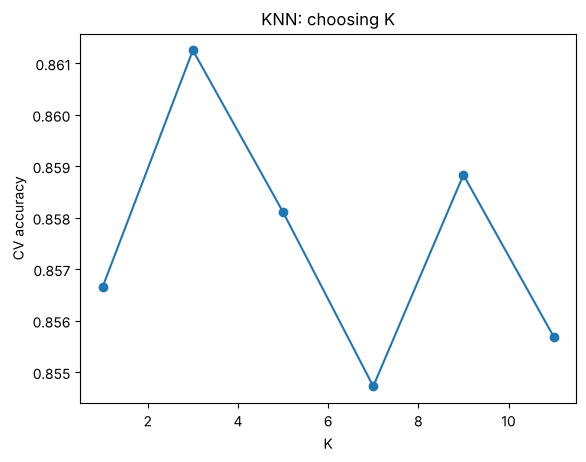

{1: np.float64(0.8567), 3: np.float64(0.8613), 5: np.float64(0.8581), 7: np.float64(0.8547), 9: np.float64(0.8588), 11: np.float64(0.8557)} -> best K = 3



KNN time (fit+predict): 1.25s


In [4]:
ks = [1, 3, 5, 7, 9, 11]
scores = [cross_val_score(KNeighborsClassifier(n_neighbors=k), X_train, y_train, cv=5, n_jobs=-1).mean() for k in ks]
best_k = ks[int(np.argmax(scores))]
plt.plot(ks, scores, marker="o"); plt.xlabel("K"); plt.ylabel("CV accuracy"); plt.title("KNN: choosing K"); plt.show()
print(dict(zip(ks, np.round(scores, 4))), "-> best K =", best_k)

t = time.time()
knn = KNeighborsClassifier(n_neighbors=best_k).fit(X_train, y_train)
knn_pred = knn.predict(X_test)
knn_time = time.time() - t
print(f"\nKNN time (fit+predict): {knn_time:.2f}s")

## 3. Support Vector Machine
Compare a linear and an RBF kernel.

In [5]:
results = {}
for kernel in ["linear", "rbf"]:
    t = time.time()
    m = SVC(kernel=kernel, C=1.0, gamma="scale").fit(X_train, y_train)
    p = m.predict(X_test)
    results[kernel] = (m, p, time.time() - t)
    print(f"SVM {kernel:6s}: accuracy={accuracy_score(y_test, p):.4f}  time={results[kernel][2]:.2f}s")

SVM linear: accuracy=0.9671  time=9.21s


SVM rbf   : accuracy=0.8126  time=32.11s


## 4. Performance comparison

In [6]:
svm_name = max(results, key=lambda k: accuracy_score(y_test, results[k][1]))
svm_pred = results[svm_name][1]
print("Best SVM kernel:", svm_name)

models = {f"KNN (K={best_k})": (knn_pred, knn_time), f"SVM ({svm_name})": (svm_pred, results[svm_name][2])}
rows = []
for n, (p, tm) in models.items():
    rows.append({"Model": n, "Accuracy": accuracy_score(y_test, p), "Precision": precision_score(y_test, p),
                 "Recall": recall_score(y_test, p), "F1": f1_score(y_test, p), "Time (s)": tm})
comp = pd.DataFrame(rows).set_index("Model").round(4)
comp

Best SVM kernel: linear


,Accuracy,Precision,Recall,F1,Time (s)
Model,,,,,
KNN (K=3),0.8676,0.7309,0.86,0.7902,1.2512
SVM (linear),0.9671,0.9375,0.95,0.9437,9.2078


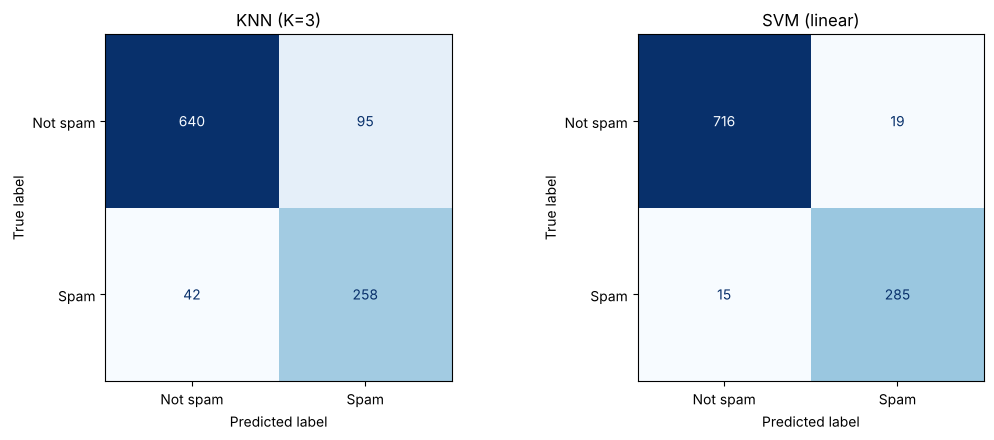

 KNN (K=3)
              precision    recall  f1-score   support

    Not spam       0.94      0.87      0.90       735
        Spam       0.73      0.86      0.79       300

    accuracy                           0.87      1035
   macro avg       0.83      0.87      0.85      1035
weighted avg       0.88      0.87      0.87      1035

 SVM (linear)
              precision    recall  f1-score   support

    Not spam       0.98      0.97      0.98       735
        Spam       0.94      0.95      0.94       300

    accuracy                           0.97      1035
   macro avg       0.96      0.96      0.96      1035
weighted avg       0.97      0.97      0.97      1035



In [7]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4.5))
for a, (n, (p, _)) in zip(ax, models.items()):
    ConfusionMatrixDisplay(confusion_matrix(y_test, p), display_labels=["Not spam","Spam"]).plot(ax=a, cmap="Blues", colorbar=False)
    a.set_title(n)
plt.tight_layout(); plt.show()

for n, (p, _) in models.items():
    print("=" * 55, "\n", n); print(classification_report(y_test, p, target_names=["Not spam", "Spam"]))

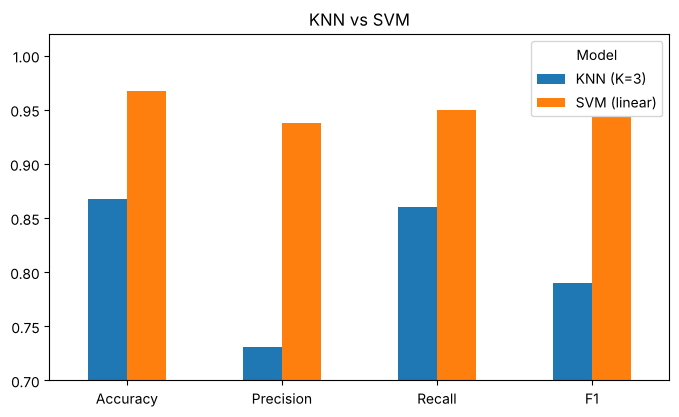

In [8]:
comp[["Accuracy","Precision","Recall","F1"]].T.plot.bar(figsize=(8,4.5), rot=0)
plt.ylim(0.7, 1.02); plt.title("KNN vs SVM"); plt.show()

## Analysis
- **Linear SVM is clearly better**: accuracy 0.967, precision 0.94, recall 0.95 for spam, vs KNN at accuracy 0.868, precision 0.73, recall 0.86.
- KNN struggles in 3000 dimensions (curse of dimensionality: distances stop being meaningful). Its low spam precision means many genuine emails would be flagged as spam.
- The RBF SVM scored only 0.813 because it is poorly suited to raw, unscaled count data with default settings; the linear kernel fits text data much better.
- Cost: KNN trains instantly but predicts slowly; the linear SVM took ~9 s to train. Both are acceptable for 5,172 emails.